# Unit 7 – Perceptron learning the AND operator
AND is linearly separable, so a perceptron should find weights that reproduce its truth table. XOR is not, and serves as a contrast.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(42)

In [2]:
def train(X, y, lr=0.1, epochs=100, verbose=False):
    w = np.zeros(2); b = 0.0; history = []
    for ep in range(1, epochs + 1):
        errs = 0
        for xi, ti in zip(X, y):
            out = int(xi @ w + b > 0)
            w = np.round(w + lr * (ti - out) * xi, 10); b = round(b + lr * (ti - out), 10); errs += int(ti != out)
        history.append((ep, w.copy(), b, errs))
        if verbose: print(f'epoch {ep}: w={w.round(2)}, b={b:.2f}, errors={errs}')
        if errs == 0: break
    return w, b, history

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])
w, b, hist = train(X, y_and, verbose=True)
print('\nLearned: w =', w, ' b =', b)
pd.DataFrame({'x1': X[:, 0], 'x2': X[:, 1], 'AND target': y_and, 'z = w·x + b': X @ w + b,
              'prediction': (X @ w + b > 0).astype(int)})

epoch 1: w=[0.1 0.1], b=0.10, errors=1
epoch 2: w=[0.2 0.1], b=0.00, errors=3
epoch 3: w=[0.2 0.1], b=-0.10, errors=3
epoch 4: w=[0.2 0.2], b=-0.10, errors=2
epoch 5: w=[0.2 0.1], b=-0.20, errors=1
epoch 6: w=[0.2 0.1], b=-0.20, errors=0

Learned: w = [0.2 0.1]  b = -0.2


,x1,x2,AND target,z = w·x + b,prediction
0,0,0,0,-0.2,0
1,0,1,0,-0.1,0
2,1,0,0,0.0,0
3,1,1,1,0.1,1


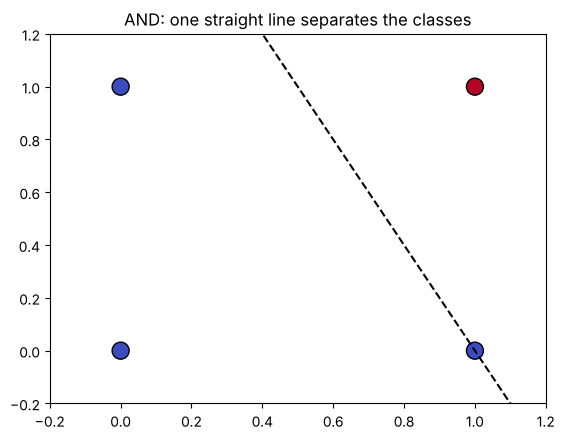

In [3]:
plt.scatter(X[:, 0], X[:, 1], c=y_and, cmap='coolwarm', s=150, edgecolors='k')
xx = np.linspace(-.2, 1.2, 10); plt.plot(xx, -(w[0] * xx + b) / w[1], 'k--')
plt.xlim(-.2, 1.2); plt.ylim(-.2, 1.2); plt.title('AND: one straight line separates the classes'); plt.show()

## Experiment – learning rate, OR vs AND vs XOR

In [4]:
rows = []
for name, target in {'AND': [0, 0, 0, 1], 'OR': [0, 1, 1, 1], 'XOR': [0, 1, 1, 0]}.items():
    for lr in (0.01, 0.1, 1.0):
        w_, b_, h = train(X, np.array(target), lr=lr, epochs=100)
        rows.append({'gate': name, 'lr': lr, 'epochs_run': len(h), 'final_errors': h[-1][3]})
pd.DataFrame(rows)

,gate,lr,epochs_run,final_errors
0,AND,0.01,6,0
1,AND,0.10,6,0
2,AND,1.00,6,0
3,OR,0.01,4,0
4,OR,0.10,4,0
5,OR,1.00,4,0
6,XOR,0.01,100,4
7,XOR,0.10,100,4
8,XOR,1.00,100,4


## Observations
* The perceptron learned AND in 6 epochs, ending with w = [0.2, 0.1], b = -0.2, which reproduces the whole truth table.
* The learning rate (0.01, 0.1, 1.0) did not change the epochs needed for AND (6 in every case) or OR (4).
* XOR never converged: 4 mistakes remained in every run after 100 epochs, whatever the learning rate. No single straight line separates XOR.